# Supplied Lecture 13A reference

Teaching material retained for attribution/context, not an original project result. Training is disabled by default. See [course context](../course-context.md).

In [ ]:
RUN_REFERENCE_TRAINING = False


In [1]:
import gymnasium as gym
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Configuration paramaters for the whole setup
gamma = 0.99  # Discount factor for past rewards
epsilon = 1.0  # Epsilon greedy parameter
epsilon_min = 0.01  # Minimum epsilon greedy parameter
epsilon_max = 1.0  # Maximum epsilon greedy parameter
epsilon_interval = (
    epsilon_max - epsilon_min
)  # Rate at which to reduce chance of random action being taken
batch_size = 64  # Size of batch taken from replay buffer
max_steps_per_episode = 1_000

# Use the Baseline Atari environment because of Deepmind helper functions
env = gym.make("CartPole-v1")

In [ ]:
num_actions = 2

def create_q_model():
    inputs = layers.Input(shape=(4,))

    x = layers.Dense(256, activation="relu")(inputs)
    x = layers.Dense(256, activation="relu")(x)
    
    actions = layers.Dense(num_actions, activation="linear")(x)
    
    model = keras.Model(inputs=inputs, outputs=actions)
    
    model.compile(
        optimizer = keras.optimizers.RMSprop(learning_rate = 0.00025, clipnorm=1.0),
        loss = "mse"
    )

    return model


# The first model makes the predictions for Q-values which are used to
# make a action.
model = create_q_model()
# Build a target model for the prediction of future rewards.
# The weights of a target model get updated every 125 steps thus when the
# loss between the Q-values is calculated the target Q-value is stable.
model_target = create_q_model()

In [ ]:
# Experience replay buffers
action_history = []
state_history = []
state_next_history = []
rewards_history = []
done_history = []
episode_reward_history = []
running_reward_history = []

# Counters
running_reward = 0
episode_count = 0
step_count = 0

# Number of episodes to take random action and observe output
pure_exploration_episodes = 200
# Number of episodes for eps-greedy exploration
epsilon_greedy_episodes = 500
# Maximum replay length
# Note: The Deepmind paper suggests 1000000 however this causes memory issues
max_memory_length = 100000
max_memory_length = 50_000
# How often to update the target network
update_target_network = 125

while RUN_REFERENCE_TRAINING:  # Explicit opt-in; historical unbounded loop
    state, info = env.reset()
    state = np.array(state)
    episode_reward = 0
    done = False
    truncated = False
    
    while not (done or truncated):
        # Use epsilon-greedy for exploration
        if np.random.random() < epsilon:
            # Take random action
            action = np.random.choice(num_actions)
        else:
            # Predict action Q-values
            # From environment state
            state_tensor = tf.convert_to_tensor(state)
            state_tensor = tf.expand_dims(state_tensor, 0)
            action_vals = model(state_tensor, training=False)
            # Take best action
            action = tf.argmax(action_vals[0]).numpy()

        # Apply the sampled action in our environment
        state_next, reward, done, truncated, info = env.step(action)
        state_next = np.array(state_next)

        episode_reward += reward

        # Save actions and states in replay buffer
        action_history.append(action)
        state_history.append(state)
        state_next_history.append(state_next)
        done_history.append(done)
        rewards_history.append(reward)
        state = state_next

        # Update once batch size is over 64
        if len(done_history) > batch_size:
            # Get indices of samples for replay buffers
            indices = np.random.choice(range(len(done_history)), size=batch_size)

            # Using list comprehension to sample from replay buffer
            state_sample = np.array([state_history[i] for i in indices])
            state_next_sample = np.array([state_next_history[i] for i in indices])
            rewards_sample = [rewards_history[i] for i in indices]
            action_sample = [action_history[i] for i in indices]
            done_sample = tf.convert_to_tensor(
                [float(done_history[i]) for i in indices]
            )

            # Build the updated Q-values for the sampled future states
            # Use the target model for stability
            future_rewards = model_target.predict(state_next_sample, verbose=0)
            
            # Q value = reward + discount factor * expected future reward
            updated_q_values = rewards_sample + gamma * tf.reduce_max(
                future_rewards, axis=1
            ) * (1 - done_sample)
            
            # Train the model on the states and updated Q-values
            q_values = model(state_sample)

            # Create a mask so we only calculate loss on the updated Q-values
            masks = tf.one_hot(action_sample, num_actions)

            new_q_values = (
                tf.multiply(q_values, (1 - masks)) + tf.multiply(tf.expand_dims(updated_q_values, -1), masks)
            )
            
            loss = model.fit(state_sample, new_q_values, batch_size = batch_size, shuffle = False, verbose = 0)

        # Limit the state and reward history
        if len(rewards_history) > max_memory_length:
            del rewards_history[:1]
            del state_history[:1]
            del state_next_history[:1]
            del action_history[:1]
            del done_history[:1]
    
        step_count += 1
        if step_count % update_target_network == 0:
            # update the the target network with new weights
            model_target.set_weights(model.get_weights())
        
        # Free up memory.
        tf.keras.backend.clear_session()
    
    episode_count += 1
    if episode_count >= pure_exploration_episodes * 0:
        epsilon += - epsilon_interval / epsilon_greedy_episodes
    epsilon = max(epsilon, epsilon_min)
        
    # Update running reward to check condition for solving
    episode_reward_history.append(episode_reward)
    if len(episode_reward_history) > 100:
        del episode_reward_history[:1]
        
    running_reward = np.mean(episode_reward_history)
    running_reward_history.append(running_reward)
    
    # Log details
    message = f"Running reward: {running_reward:.2f} at episode {episode_count}, eps = {epsilon:.4f}"
    print(message)

    if running_reward > 220:  # Condition to consider the task solved
        # Standard condition is running_reward > 200 for CartPole.
        # Changed to 220 here to showcase what happens to the running
        # reward after solving the task.
        print("Solved at episode {}!".format(episode_count))
        break

Running reward: 13.00 at episode 1, eps = 0.9980
Running reward: 16.00 at episode 2, eps = 0.9960
Running reward: 21.67 at episode 3, eps = 0.9941
Running reward: 18.75 at episode 4, eps = 0.9921
Running reward: 19.60 at episode 5, eps = 0.9901
Running reward: 19.67 at episode 6, eps = 0.9881
Running reward: 19.71 at episode 7, eps = 0.9861
Running reward: 19.62 at episode 8, eps = 0.9842
Running reward: 18.78 at episode 9, eps = 0.9822
Running reward: 21.60 at episode 10, eps = 0.9802
Running reward: 24.73 at episode 11, eps = 0.9782
Running reward: 24.08 at episode 12, eps = 0.9762
Running reward: 24.23 at episode 13, eps = 0.9743
Running reward: 24.64 at episode 14, eps = 0.9723
Running reward: 24.07 at episode 15, eps = 0.9703
Running reward: 26.25 at episode 16, eps = 0.9683
Running reward: 27.12 at episode 17, eps = 0.9663
Running reward: 26.28 at episode 18, eps = 0.9644
Running reward: 26.47 at episode 19, eps = 0.9624
Running reward: 25.95 at episode 20, eps = 0.9604
Running r

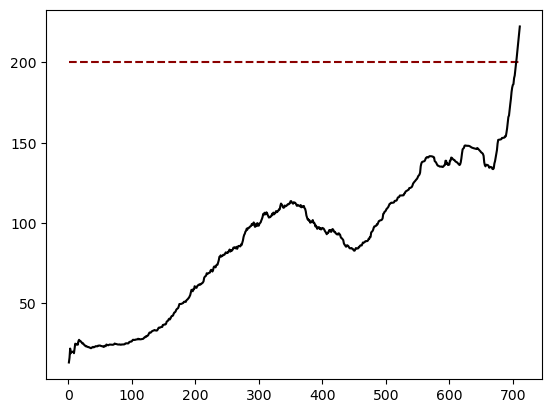

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

yy = np.array(running_reward_history)
xx = np.arange(1, len(yy) + 1)

fig = plt.figure()
ax = sns.lineplot(
    x=xx,
    y=200,
    color="darkred",
    linestyle="dashed"
)
ax = sns.lineplot(
    x=xx,
    y=yy,
    color="black"
)
plt.show()